# Технологии нейросетевых вычислений



##ЛР4. Рекуррентные нейронные сети. Предобработка текста (10 баллов + 2 балла бонусных)

# О формате сдачи

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

# Задание

В этом задании будем определять тональность сообщений, используя техники предобработки текста и рекуррентные сети.

Установим и импортируем необходимые библиотеки.

In [ ]:
!pip install pymorphy2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 53.4 MB/s  0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=c119b031eda748ea4ee42c11207970492ab9a82199da762713bb02427ba9c5e3
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pymorphy2]


In [ ]:
import os
import pandas as pd
from collections import defaultdict
import time

import re
import pymorphy2
import nltk
from nltk.corpus import stopwords

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

Будем классифицировать тон комментариев, связанных с коронавирусом. Давайте скачаем их с диска

In [ ]:
!pip install gdown > /dev/null
!gdown https://drive.google.com/uc?id=145ZCFU-b65Xbjsh16fPepF_N66X0kZj2
!unzip -n coronavirus_archive.zip > /dev/null

Downloading...
From: https://drive.google.com/uc?id=145ZCFU-b65Xbjsh16fPepF_N66X0kZj2
To: /content/coronavirus_archive.zip
100% 4.60M/4.60M [00:00<00:00, 113MB/s]


In [ ]:
df_train = pd.read_csv("Corona_NLP_train.csv", encoding='ISO-8859-1')
df_test = pd.read_csv("Corona_NLP_test.csv", encoding='ISO-8859-1')

df_train.head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative


Нам понадобятся колонки `OriginalTweet` и `Sentiment`.

In [ ]:
df_train = df_train[['OriginalTweet', 'Sentiment']]
df_test = df_test[['OriginalTweet', 'Sentiment']]

df_train = df_train.dropna()
df_test = df_test.dropna()

df_train['Sentiment'].value_counts()

,count
Sentiment,
Positive,11422
Negative,9917
Neutral,7713
Extremely Positive,6624
Extremely Negative,5481


Давайте рассмотрим на один из твиттов в данных:

In [ ]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[0]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[0]}")

TWEET TEXT: @MeNyrbie @Phil_Gahan @Chrisitv https://t.co/iFz9FAn2Pa and https://t.co/xX6ghGFzCC and https://t.co/I2NlzdxNo8
CATEGORY: Neutral


Как вы можете заметить, текст может вообще не содержать хоть сколько-нибудь полезной информации и состоять исключительно из ссылок и отметок

In [ ]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[1]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[1]}")

TWEET TEXT: advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order
CATEGORY: Positive


А могут быть и вполне себе осмысленные предложения.

In [ ]:
print(f"TWEET TEXT: {df_train['OriginalTweet'].iloc[4]}")
print(f"CATEGORY: {df_train['Sentiment'].iloc[4]}")





#CoronavirusFrance #restezchezvous #StayAtHome #confinement https://t.co/usmuaLq72n
CATEGORY: Extremely Negative


А иногда в тексте содержится и то, и другое. Возможно, внутри твитов есть и другие паттерны. Например, обратите внимание на хештеги.

## <font color='DarkOrange'> **Задание 1 [1 балл]** </font>

Выполним токенизацию (разделение текста на токены - например, отдельные слова являются токенами для предложения). Далее токены нужно перевести в формат числовых векторов (выполнить векторизацию). Иногда токенизацию+векторизацию заменяют в речи для краткости одним из этих слов - как синоним предобработки.

Напишите функцию `tokenize`, которая преобразовывает текст в список токенов-слов. При этом:

1. Текст должен быть приведен к нижнему регистру.
2. Должны быть удалены стоп-слова.
3. Возможно, должны быть удалены некоторые конкретные символы (на ваше усмотрение)

Используем `Natural Language Toolkit`

In [ ]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
punctuation = re.compile(r'[^a-zA-Z\s]')

def tokenize(text):
    text = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", text.lower())
    text = punctuation.sub(" ", text)
    retained = {"no", "nor", "not", "cannot"}
    tokens = [word for word in text.split() if word not in stop_words or word in retained]
    return tokens

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Преобразуем нужные колонки.

In [ ]:
from sklearn.model_selection import train_test_split

df_train, df_val = train_test_split(
    df_train, test_size=0.15, stratify=df_train['Sentiment'], random_state=42)
df_train, df_val, df_test = (frame.copy() for frame in (df_train, df_val, df_test))
for frame in (df_train, df_val, df_test):
    frame['tokenized'] = frame['OriginalTweet'].apply(tokenize)

In [ ]:
assert isinstance(df_train['tokenized'].iloc[0], list)

## <font color='DarkOrange'> **Задание 2 [2 балла]** </font>

Теперь создайте словарь со всеми токенами в тексте и их частотами встречаемости:

In [ ]:
from collections import Counter
counter_tokens = Counter(token for tokens in df_train["tokenized"] for token in tokens)
print(counter_tokens.most_common(10))

[('covid', 19725), ('coronavirus', 15463), ('prices', 6738), ('food', 6135), ('supermarket', 6036), ('store', 5894), ('grocery', 5349), ('people', 4784), ('amp', 4407), ('consumer', 3946)]


Для работы с текстами необходимо зарезервировать два специальных токена:

1. `<pad>` для токена, означающего паддинг
1. `<unk>` для токенов, которые отсутствуют в словаре

Добавьте указанные токены в ваш словарь.

In [ ]:
specials = ['<pad>', '<unk>']

Теперь напишите функцию, которая принимает на вход словарь "слово-частота", выдаёт список токенов (слов) itos, которые упорядочены по убыванию частоты встречаемости, а также словарь "слово-ранг" как enumerate для itos. Ограничим эти контейнеры длиной max_size

In [ ]:
def make_dict(counter, specials, max_size=5000):
    if max_size < len(specials):
        raise ValueError('max_size должен вмещать все специальные токены')
    if len(set(specials)) != len(specials):
        raise ValueError('Специальные токены должны быть уникальными')
    # При совпадении частот лексический порядок обеспечивает воспроизводимость.
    words = sorted((word for word in counter if word not in specials),
                   key=lambda word: (-counter[word], word))
    itos = list(specials) + words[:max_size - len(specials)]
    stoi = {word: index for index, word in enumerate(itos)}
    return stoi, itos

Воспользуемся функцией, чтобы получить нужный словарь и список.

In [ ]:
stoi, itos = make_dict(counter_tokens, specials)
stoi['<pad>']

0

## <font color='DarkOrange'> **Задание 3 [2 балла]** </font>

Наконец вам необходимо создать обёртку-датасет для данных.

Уже добавлены несколько опций, которые понадобятся далее:

1. Ограничение на максимальную длину текста в токенах. Если текст оказывается длиннее, то последние токены отбрасываются.
2. Возможность добавить специальные токены <sos>, <eos> в начало и конец токенизированного текста.

Заполните оставшиеся строки. Лейблы необходимо перекодировать в числовой вид и сохранить в виде тензора.

In [ ]:
class ReviewDataset(Dataset):
    def __init__(self, data,
                 max_len,
                 stoi, itos,
                 token_column='tokenized',
                 label_column='Sentiment',
                 pad_sos=False, pad_eos=False):
        """
        :param data: data
        :param int max_len: Maximum length of tokenized text
        :param bool pad_sos: If True pad sequence at the beginning with <sos>
        :param bool pad_eos: If True pad sequence at the end with <eos>
        """
        super().__init__()

        self.stoi = stoi.copy()
        self.itos = itos.copy()
        self.pad_sos = pad_sos
        if self.pad_sos:
            self.itos.append('<sos>')
            self.stoi['<sos>'] = len(self.itos)
            self.sos_id = len(self.itos)
        self.pad_eos = pad_eos
        if self.pad_eos:
            self.itos.append('<eos>')
            self.stoi['<eos>'] = len(self.itos)
            self.eos_id = len(self.itos)

        self.max_len = max_len
        self.data = data.copy()

        self.texts = []
        self.tokens = []

        sentiment_mapping = {
            'Extremely Positive': 4,
            'Positive': 3,
            'Neutral': 2,
            'Negative': 1,
            'Extremely Negative': 0}

        # используйте sentiment_mapping
        self.labels = torch.tensor(data[label_column].map(sentiment_mapping).to_numpy(), dtype=torch.long)
        self.tokens_len = []

        # Ваш код
        for i, row in data.iterrows():
            self.texts.append(row['OriginalTweet'])
            token_ids = self.lookup_indices(row[token_column][:self.max_len])
            if self.pad_sos:
                token_ids.insert(0, self.sos_id)
            if self.pad_eos:
                token_ids.append(self.eos_id)
            if not token_ids:
                token_ids = [self.stoi['<unk>']]
            self.tokens.append(torch.tensor(token_ids, dtype=torch.long)) # сами токены
            self.tokens_len.append(torch.tensor(len(token_ids), dtype=torch.long)) # кол-во токенов

    def __getitem__(self, idx):
        """
        :param int idx: index of object in dataset
        :return dict: Dictionary with all useful object data
            {
                'text' str: unprocessed text,
                'label' torch.tensor(dtype=torch.long): sentiment of the text (0 for negative, 1 for positive)
                'tokens' torch.tensor(dtype=torch.long): tensor of tokens ids for the text
                'tokens_len' torch.tensor(dtype=torch.long): number of tokens
            }
        """
        return {
            'text': self.texts[idx],
            'label': self.labels[idx],
            'tokens': self.tokens[idx],
            'tokens_len': self.tokens_len[idx]}

    def __len__(self):
        """
        :return int: number of objects in dataset
        """
        return len(self.data)

    def lookup_indices(self, text_list):
      """
      :return list: List with indices for each token in token_list with '<unk>' for unknown tokens
      """
      return  [self.stoi.get(token, self.stoi['<unk>']) for token in text_list]


In [ ]:
train_dataset = ReviewDataset(df_train, 200, stoi, itos)
test_dataset = ReviewDataset(df_test, 200, stoi, itos)
val_dataset = ReviewDataset(df_val, 200, stoi, itos)

Посмотрим, как выглядит объект в датасете:

In [ ]:
test_dataset[0]

{'text': 'TRENDING: New Yorkers encounter empty supermarket shelves (pictured, Wegmans in Brooklyn), sold-out online grocers (FoodKick, MaxDelivery) as #coronavirus-fearing shoppers stock up https://t.co/Gr76pcrLWh https://t.co/ivMKMsqdT1',
 'label': tensor(0),
 'tokens': tensor([2064,   36,    1,    1,  135,    6,   52,    1,    1, 3402,  479,   14,
         1829,    1,    1,    3,    1,  241,   30]),
 'tokens_len': tensor(19)}

In [ ]:
assert set(test_dataset[0].keys()) == set(['text', 'label', 'tokens', 'tokens_len'])

## <font color='DarkOrange'> **Задание 4 [2 балла]** </font>

Теперь нужно создать `DataLoader` для данных. Зададим кастомную функцию `collate_fn` - как объединить сэмплы в батч. Чтобы объединить несколько тензоров разной длины в один, воспользуйтесь функцией `torch.nn.utils.rnn.pad_sequence`.

In [ ]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch, padding_value, batch_first=False):
    batch = [elem for elem in batch if elem['tokens_len'].item() > 0]
    if len(batch) == 0:
        raise ValueError("Batch contains only empty sequences.")

    labels = [elem['label'].item() for elem in batch]
    texts = [elem['text'] for elem in batch]
    tokens = [elem['tokens'] for elem in batch]
    tokens_lens = [elem['tokens_len'].item() for elem in batch]
    tokens = pad_sequence(tokens, batch_first=batch_first, padding_value=padding_value)

    if not batch_first:
        tokens = tokens.transpose(0, 1)

    return {
        'labels': torch.tensor(labels, dtype=torch.long),
        'tokens': tokens,
        'tokens_lens': torch.tensor(tokens_lens, dtype=torch.long),
        'texts': texts
    }

Наконец создадим даталоадеры.

In [ ]:
from functools import partial

new_col = partial(collate_fn, padding_value=stoi['<pad>'], batch_first=True)

test_dataloader = DataLoader(test_dataset, batch_size=64,
                             collate_fn=new_col, shuffle=False, num_workers=0)
train_dataloader = DataLoader(train_dataset, batch_size=64,
                              collate_fn=new_col, shuffle=True, num_workers=0)
val_dataloader = DataLoader(val_dataset, batch_size=64, collate_fn=new_col, shuffle=False, num_workers=0)

Давайте посмотрим на какой-нибудь батч:

In [ ]:
batch = next(iter(test_dataloader))
print(batch.keys())
print(f"labels: {batch['labels']}")
print(f"tokens: {batch['tokens']}")
print(f"tokens_lens: {batch['tokens_lens']}")

dict_keys(['labels', 'tokens', 'tokens_lens', 'texts'])
labels: tensor([0, 3, 4, 1, 2, 2, 3, 2, 0, 4, 3, 0, 0, 4, 3, 0, 4, 2, 3, 4, 1, 4, 4, 4,
        0, 3, 1, 1, 1, 3, 1, 4, 0, 0, 2, 0, 1, 2, 1, 4, 3, 1, 2, 3, 3, 4, 4, 0,
        0, 0, 0, 2, 1, 4, 0, 1, 1, 3, 3, 2, 0, 0, 4, 0])
tokens: tensor([[2064,   36,    1,  ...,    0,    0,    0],
        [ 120,   29,   22,  ...,    0,    0,    0],
        [ 120,  198, 1645,  ...,    0,    0,    0],
        ...,
        [4053,    1, 3234,  ...,    0,    0,    0],
        [1052,    3,    2,  ...,    0,    0,    0],
        [ 357,   35,    4,  ...,    0,    0,    0]])
tokens_lens: tensor([19, 14,  5, 28, 23, 17,  6, 20, 28, 19, 17, 18, 25, 24, 17, 22, 19, 17,
        24, 28, 24, 23, 24, 20, 25, 20, 16, 31, 22, 16, 25, 13, 24, 35, 13, 35,
        30, 20, 25, 27, 22, 23, 26, 12, 15, 27, 20, 17, 29, 30, 22, 20, 23, 21,
        25, 30,  8,  8, 20, 13, 28, 26, 23, 24])



Нейросеть будет обрабатывать входную последовательность по словам (word level), имея стандартную рекуррентную архитектуру для классификации:

1. Слой представлений, превращающий id токена в вектор-эмбеддинг этого слова
2. Слой RNN
3. Полносвязный слой, предсказывающий выход по последнему скрытому состоянию

Допишите код (???) и прокомментируйте суть и назначение слоя с именем attention

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, embedding_dim, hidden_size, output_size, vocab, rec_layer=nn.LSTM, num_layers=2, dropout=0.3, bidirectional=True):
        super(RNNClassifier, self).__init__()
        self.vocab = vocab
        self.hidden_size = hidden_size
        self.embedding_dim = embedding_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(len(vocab), embedding_dim, padding_idx=vocab['<pad>'])

        self.rnn = rec_layer(
           input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers,
           dropout=dropout if num_layers > 1 else 0, batch_first=True,
           bidirectional=bidirectional
        )

        self.attention = nn.Linear(hidden_size * (2 if bidirectional else 1), 1)
        self.fc = nn.Linear(hidden_size * (2 if bidirectional else 1), output_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, tokens, tokens_lens):
        embedded = self.embedding(tokens)
        embedded = self.dropout(embedded)
        packed_output, (hidden, cell) = self.rnn(embedded)

        if self.bidirectional:
            hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            hidden = hidden[-1]

        attn_weights = torch.sigmoid(self.attention(hidden))
        hidden = hidden * attn_weights
        hidden = self.dropout(hidden)
        output = self.fc(hidden)

        return output

In [ ]:
if torch.cuda.is_available():
    device = 'cuda'
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

Using device: cuda


## <font color='DarkOrange'> **Задание 5 [2 балла]** </font>

Также дозаполните необходимые строки в `train_epoch` и `evaluate`.

In [ ]:
def train_epoch(dataloader, model, loss_fn, optimizer, device):
    model.train()
    for idx, data in enumerate(dataloader):
        tokens, tokens_lens = data['tokens'].to(device), data['tokens_lens']
        labels = data['labels'].to(device)
        optimizer.zero_grad()
        outputs = model(tokens, tokens_lens)
        loss = loss_fn(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()


def evaluate(dataloader, model, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_accuracy = 0.0
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            tokens, tokens_lens = data['tokens'].to(device), data['tokens_lens']
            labels = data['labels'].to(device)
            outputs = model(tokens, tokens_lens)
            total_loss += loss_fn(outputs, labels).item() * labels.size(0)
            total_accuracy += (outputs.argmax(dim=1) == labels).sum().item()

    return total_loss / len(dataloader.dataset), total_accuracy / len(dataloader.dataset)

def train(
    train_loader, test_loader, model, loss_fn, optimizer, device, num_epochs
):
    test_losses = []
    train_losses = []
    test_accuracies = []
    train_accuracies = []
    time_it = []
    start = time.time()
    for epoch in range(num_epochs):
        start = time.time()
        train_epoch(train_loader, model, loss_fn, optimizer, device)
        train_loss, train_acc = evaluate(train_loader, model, loss_fn, device)
        train_accuracies.append(train_acc)
        train_losses.append(train_loss)

        test_loss, test_acc = evaluate(test_loader, model, loss_fn, device)
        test_accuracies.append(test_acc)
        test_losses.append(test_loss)
        time_it.append(time.time() - start)

        print(
            'Epoch: {0:d}/{1:d}. Loss (Train/Test): {2:.3f}/{3:.3f}. Accuracy (Train/Test): {4:.3f}/{5:.3f}'.format(
                epoch + 1, num_epochs, train_losses[-1], test_losses[-1], train_accuracies[-1], test_accuracies[-1]
            )
        )
    return train_losses, train_accuracies, test_losses, test_accuracies, time_it

Создайте модель, функцию потерь и оптимизатор.
Допишите код (???)

In [ ]:
from torch.optim import AdamW

In [ ]:
embedding_dim = 128
hidden_size = 256
output_size = 5
model_lstm = RNNClassifier(embedding_dim, hidden_size, output_size, stoi)
model_lstm.to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = AdamW(model_lstm.parameters(), lr=0.001, weight_decay=1e-4)

Обучите модель:

In [ ]:
train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_lstm, loss_fn, optimizer, device, 10
)

Epoch: 1/10. Loss (Train/Test): 1.076/1.171. Accuracy (Train/Test): 0.559/0.514
Epoch: 2/10. Loss (Train/Test): 0.789/0.927. Accuracy (Train/Test): 0.706/0.651
Epoch: 3/10. Loss (Train/Test): 0.639/0.802. Accuracy (Train/Test): 0.774/0.704
Epoch: 4/10. Loss (Train/Test): 0.561/0.752. Accuracy (Train/Test): 0.804/0.733
Epoch: 5/10. Loss (Train/Test): 0.493/0.710. Accuracy (Train/Test): 0.831/0.749
Epoch: 6/10. Loss (Train/Test): 0.439/0.720. Accuracy (Train/Test): 0.848/0.755
Epoch: 7/10. Loss (Train/Test): 0.381/0.709. Accuracy (Train/Test): 0.865/0.754
Epoch: 8/10. Loss (Train/Test): 0.338/0.750. Accuracy (Train/Test): 0.877/0.749
Epoch: 9/10. Loss (Train/Test): 0.286/0.751. Accuracy (Train/Test): 0.900/0.759
Epoch: 10/10. Loss (Train/Test): 0.245/0.805. Accuracy (Train/Test): 0.911/0.755


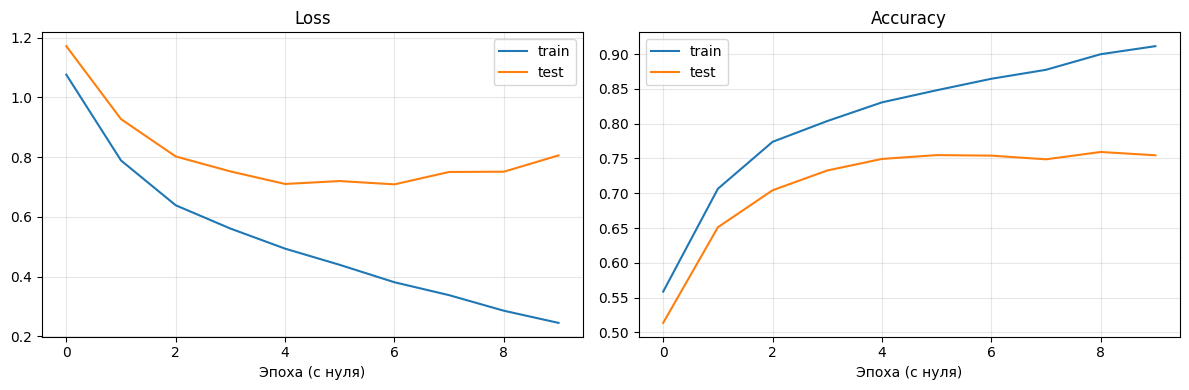

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, train_values, test_values, title in zip(
    axes, [train_losses_pure, train_accuracies_pure],
    [test_losses_pure, test_accuracies_pure], ['Loss', 'Accuracy']):
    ax.plot(train_values, label='train')
    ax.plot(test_values, label='test')
    ax.set_xlabel('Эпоха (с нуля)'); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Давайте посмотрим на качество, которое у нас получилось.

In [ ]:
def return_outputs(model, dataloader):
    model.eval()

    labels_all = []
    outputs_all = []
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            tokens, tokens_lens = data['tokens'].to(device), data['tokens_lens'].to(device)
            labels = data['labels']
            labels_all.extend(labels)
            outputs = model(tokens, tokens_lens).to('cpu')
            outputs_all.extend(outputs)
    return torch.concat([l.reshape(1) for l in labels_all]), torch.vstack(outputs_all)

In [ ]:
labels, outputs_lstm = return_outputs(model_lstm, test_dataloader)

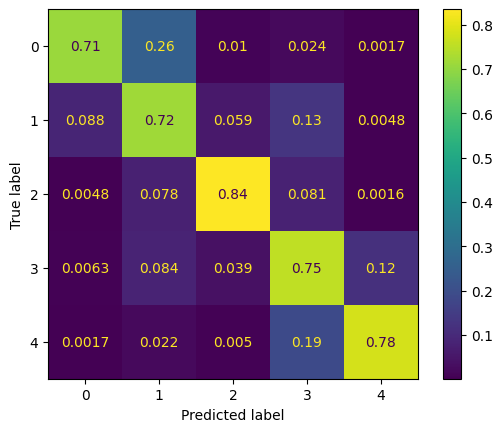

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(labels, torch.argmax(outputs_lstm, dim=1), labels=np.unique(labels),
                      normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

## <font color='MediumSeaGreen'> **Задание 6 [1 + 2 баллa]** </font>

Вычислите f1-меру. Весьма вероятно, что получится 0.7-0.75.
Дайте определение этой метрики.
Попробуйте повысить качество до 0.8: усложнить предобработку, модифицировать архитектуру, сетап обучения.

In [ ]:
from sklearn.metrics import f1_score

assert f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro') >= 0.69
print(f"result: {f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro')}")

result: 0.7636299556315017


In [ ]:
%pip install -q gdown nltk scikit-learn matplotlib pandas numpy torch


In [ ]:
previous_preparation_6_ready = globals().get('preparation_6_ready', False)
preparation_6_ready = False

import re, html, random, zipfile, urllib.request
from collections import Counter
from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
from nltk.tokenize import TweetTokenizer
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device6 = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device6)


if 'df_train' not in globals() or 'df_test' not in globals():
    raise ValueError('Сначала выполните ячейки выше, которые загружают df_train и df_test.')
columns6 = ['OriginalTweet', 'Sentiment']
try:
    train6 = df_train[columns6].dropna().copy()
    test6 = df_test[columns6].dropna().copy()
    if 'df_val' in globals() and df_val is not None:
        val6 = df_val[columns6].dropna().copy()
        print('Используется уже созданная валидационная выборка df_val.')
    else:
        train6, val6 = train_test_split(train6, test_size=0.15,
            stratify=train6['Sentiment'], random_state=SEED)
        print('df_val не найдена: 15% имеющегося df_train выделено для валидации.')
except KeyError as error:
    raise ValueError('В df_train, df_val и df_test нужны столбцы OriginalTweet и Sentiment.') from error
train6, val6, test6 = [x.reset_index(drop=True).copy() for x in (train6, val6, test6)]
# Сохраняем прежнее соответствие слов и векторов до пересоздания словаря.
previous_itos6 = globals().get('itos6')
previous_embeddings6 = globals().get('embeddings6')
print('Размеры train / val / test:', len(train6), len(val6), len(test6))


# TweetTokenizer сохраняет эмотиконы и пунктуацию, включая ! и ?.
tweet_tokenizer6 = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=False)
def tokenize6(text):
    text = html.unescape(str(text)).replace('’', "'")
    text = re.sub(r'https?://\S+|www\.\S+|@\w+', ' ', text, flags=re.I)
    text = re.sub(r'<[^>]+>', ' ', text)
    # Делим #StayAtHome на отдельные слова до перевода в нижний регистр.
    def expand_tag(match):
        tag = match.group(1).replace('_', ' ')
        tag = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', tag)
        tag = re.sub(r'(?<=[A-Z])(?=[A-Z][a-z])', ' ', tag)
        return ' ' + tag + ' '
    text = re.sub(r'#([A-Za-z0-9_]+)', expand_tag, text)
    text = re.sub(r"\bcan't\b", 'can not', text, flags=re.I)
    text = re.sub(r"\bwon't\b", 'will not', text, flags=re.I)
    text = re.sub(r"n['’]t\b", ' not', text, flags=re.I)
    return tweet_tokenizer6.tokenize(text)

for frame in (train6, val6, test6):
    frame['tokens6'] = frame['OriginalTweet'].map(tokenize6)
print('Пример:', tokenize6("Can't wait! #StayAtHome :) https://t.co/x"))

MAX_VOCAB6 = 25000
counts6 = Counter(token for row in train6['tokens6'] for token in row)
words6 = [word for word, count in sorted(counts6.items(), key=lambda p: (-p[1], p[0]))
          if word not in {'<pad>', '<unk>'}][:MAX_VOCAB6-2]
itos6 = ['<pad>', '<unk>'] + words6
stoi6 = {word: i for i, word in enumerate(itos6)}
for name, frame in [('train', train6), ('validation', val6), ('test', test6)]:
    total = sum(len(row) for row in frame['tokens6'])
    oov = sum(token not in stoi6 for row in frame['tokens6'] for token in row)
    print(f'{name}: токенов вне словаря {oov}/{total} ({oov/max(total, 1):.2%})')
print('Размер словаря:', len(stoi6))


# Используем имеющиеся векторы; архив скачивается только при их отсутствии.
EMBED_DIM6 = 300
if (previous_preparation_6_ready and previous_embeddings6 is not None and previous_itos6 is not None
        and list(previous_itos6) == itos6
        and np.shape(previous_embeddings6) == (len(itos6), EMBED_DIM6)):
    embeddings6 = np.asarray(previous_embeddings6, dtype=np.float32).copy()
    print('Используются embeddings6 из памяти с тем же словарём itos6.')
    print('Покрытие GloVe восстановить по готовой матрице нельзя.')
else:
    glove_txt6 = Path('glove.6B.300d.txt')
    glove_zip6 = Path('glove.6B.zip')
    if not glove_txt6.is_file() and not glove_zip6.is_file():
        print('Загрузка предобученных векторов GloVe (~822 МБ); данные твитов не скачиваются.')
        temporary = glove_zip6.with_suffix('.zip.part')
        urls = ['https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip',
                'https://nlp.stanford.edu/data/glove.6B.zip']
        last_error = None
        for url in urls:
            try:
                urllib.request.urlretrieve(url, temporary)
                if not zipfile.is_zipfile(temporary):
                    raise ValueError(f'Получен не ZIP-архив: {url}')
                temporary.replace(glove_zip6)
                break
            except Exception as error:
                last_error = error
                print(f'Не удалось скачать {url}: {error}')
            finally:
                if temporary.exists():
                    temporary.unlink()
        if not glove_zip6.is_file():
            raise RuntimeError('Не удалось скачать GloVe из официальных источников') from last_error
    embeddings6 = np.random.normal(0, 0.05, (len(itos6), EMBED_DIM6)).astype(np.float32)
    embeddings6[0] = 0
    found6 = set()
    def read_vectors6(stream):
        for line in stream:
            word_bytes, sep, values = line.rstrip().partition(b' ')
            if not sep:
                continue
            word = word_bytes.decode('utf-8', errors='replace')
            index = stoi6.get(word)
            if index is not None and index >= 2:
                vector = np.fromstring(values.decode('ascii'), sep=' ', dtype=np.float32)
                if vector.size == EMBED_DIM6:
                    embeddings6[index] = vector
                    found6.add(word)
    if glove_txt6.is_file():
        with glove_txt6.open('rb') as stream:
            read_vectors6(stream)
    else:
        with zipfile.ZipFile(glove_zip6) as archive:
            with archive.open('glove.6B.300d.txt') as stream:
                read_vectors6(stream)
    print(f'GloVe: найдено {len(found6)} из {len(itos6)-2} слов словаря ({len(found6)/max(len(itos6)-2, 1):.2%})')
    total_train_tokens6 = sum(counts6.values())
    covered_train6 = sum(counts6[word] for word in found6)
    print(f'Покрытие GloVe по числу токенов train: {covered_train6}/{total_train_tokens6} ({covered_train6/max(total_train_tokens6,1):.2%})')

preparation_6_ready = True
print("Подготовка задания 6 завершена.")



Устройство: cuda
Используется уже созданная валидационная выборка df_val.
Размеры train / val / test: 34983 6174 3798
Пример: ['can', 'not', 'wait', '!', 'stay', 'at', 'home', ':)']
train: токенов вне словаря 18218/1198947 (1.52%)
validation: токенов вне словаря 5942/210311 (2.83%)
test: токенов вне словаря 3403/145472 (2.34%)
Размер словаря: 25000
Загрузка предобученных векторов GloVe (~822 МБ); данные твитов не скачиваются.
GloVe: найдено 19931 из 24998 слов словаря (79.73%)
Покрытие GloVe по числу токенов train: 1124594/1198947 (93.80%)
Подготовка задания 6 завершена.


In [ ]:
# Перед созданием модели убедимся, что подготовка успешно завершилась.
if (not globals().get('preparation_6_ready', False)
        or any(name not in globals() for name in ('embeddings6', 'itos6', 'stoi6'))
        or getattr(embeddings6, 'shape', None) != (len(itos6), 300)
        or len(stoi6) != len(itos6)
        or any(stoi6.get(word) != i for i, word in enumerate(itos6))):
    raise RuntimeError('Выполните ячейку «Подготовка задания 6» и дождитесь завершения без ошибок.')

label_map6 = {'Extremely Negative': 0, 'Negative': 1, 'Neutral': 2,
              'Positive': 3, 'Extremely Positive': 4}
class TweetDataset6(Dataset):
    def __init__(self, frame):
        self.sequences = [[stoi6.get(t, 1) for t in tokens[:200]] or [1]
                          for tokens in frame['tokens6']]
        self.labels = [label_map6[label] for label in frame['Sentiment']]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return torch.tensor(self.sequences[index], dtype=torch.long), self.labels[index]

def collate6(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in seqs], dtype=torch.long)
    return pad_sequence(seqs, batch_first=True, padding_value=0), lengths, torch.tensor(labels, dtype=torch.long)

train_loader6 = DataLoader(TweetDataset6(train6), batch_size=64, shuffle=True, collate_fn=collate6)
val_loader6 = DataLoader(TweetDataset6(val6), batch_size=64, shuffle=False, collate_fn=collate6)
test_loader6 = DataLoader(TweetDataset6(test6), batch_size=64, shuffle=False, collate_fn=collate6)

class GloveBiLSTM6(nn.Module):
    def __init__(self, vectors, hidden=128, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(vectors), freeze=False, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.LSTM(vectors.shape[1], hidden, batch_first=True, bidirectional=True)
        self.attention = nn.Linear(2 * hidden, 1)
        self.output = nn.Linear(6 * hidden, 5)
    def forward(self, tokens, lengths):
        x = self.dropout(self.embedding(tokens))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.rnn(packed)
        states, _ = pad_packed_sequence(packed, batch_first=True, total_length=tokens.size(1))
        mask = torch.arange(tokens.size(1), device=tokens.device)[None, :] < lengths.to(tokens.device)[:, None]
        scores = self.attention(states).squeeze(-1).masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=1)
        attentive = (states * weights.unsqueeze(-1)).sum(dim=1)
        mean = (states * mask.unsqueeze(-1)).sum(dim=1) / lengths.to(tokens.device).unsqueeze(1)
        maximum = states.masked_fill(~mask.unsqueeze(-1), float('-inf')).max(dim=1).values
        features = torch.cat([attentive, mean, maximum], dim=1)
        return self.output(self.dropout(features))

model6 = GloveBiLSTM6(embeddings6).to(device6)
head_params6 = [p for name, p in model6.named_parameters() if not name.startswith('embedding.')]
optimizer6 = torch.optim.AdamW([
    {'params': model6.embedding.parameters(), 'lr': 0.0002},
    {'params': head_params6, 'lr': 0.001}], weight_decay=1e-4)
loss_fn6 = nn.CrossEntropyLoss()
scheduler6 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer6, mode='max', factor=0.5, patience=1)


In [ ]:
def evaluate6(loader):
    model6.eval()
    actual, predicted = [], []
    loss_total, examples = 0.0, 0
    with torch.no_grad():
        for tokens, lengths, labels in loader:
            tokens, labels = tokens.to(device6), labels.to(device6)
            logits = model6(tokens, lengths)
            loss_total += loss_fn6(logits, labels).item() * labels.size(0)
            examples += labels.size(0)
            actual.extend(labels.cpu().tolist())
            predicted.extend(logits.argmax(dim=1).cpu().tolist())
    return loss_total / examples, f1_score(actual, predicted, average='macro', zero_division=0), actual, predicted

best_f1_6, best_state6, stale6 = -1.0, None, 0
history6 = []
for epoch in range(1, 16):
    model6.train()
    running_loss, count = 0.0, 0
    for tokens, lengths, labels in train_loader6:
        tokens, labels = tokens.to(device6), labels.to(device6)
        optimizer6.zero_grad()
        logits = model6(tokens, lengths)
        loss = loss_fn6(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model6.parameters(), 1.0)
        optimizer6.step()
        running_loss += loss.item() * labels.size(0)
        count += labels.size(0)
    val_loss6, val_f1_6, _, _ = evaluate6(val_loader6)
    history6.append((running_loss / count, val_loss6, val_f1_6))
    scheduler6.step(val_f1_6)
    print(f'Эпоха {epoch:02d}: train loss={running_loss/count:.4f}, val loss={val_loss6:.4f}, val macro-F1={val_f1_6:.4f}')
    if val_f1_6 > best_f1_6:
        best_f1_6, stale6 = val_f1_6, 0
        best_state6 = {name: value.detach().cpu().clone() for name, value in model6.state_dict().items()}
        torch.save({'state_dict': best_state6, 'itos': itos6, 'label_map': label_map6,
                    'val_macro_f1': best_f1_6}, 'best_glove_bilstm.pt')
    else:
        stale6 += 1
        if stale6 >= 4:
            print('Ранняя остановка: валидационная F1 не улучшалась 4 эпохи.')
            break
model6.load_state_dict(best_state6)
print(f'Выбрана модель с validation macro-F1 = {best_f1_6:.4f}; сохранена в best_glove_bilstm.pt')


Эпоха 01: train loss=1.2430, val loss=0.9962, val macro-F1=0.6054
Эпоха 02: train loss=0.9451, val loss=0.8211, val macro-F1=0.6998
Эпоха 03: train loss=0.8014, val loss=0.7175, val macro-F1=0.7428
Эпоха 04: train loss=0.7040, val loss=0.6813, val macro-F1=0.7582
Эпоха 05: train loss=0.6266, val loss=0.6514, val macro-F1=0.7716
Эпоха 06: train loss=0.5722, val loss=0.6101, val macro-F1=0.7880
Эпоха 07: train loss=0.5181, val loss=0.5998, val macro-F1=0.7905
Эпоха 08: train loss=0.4726, val loss=0.5817, val macro-F1=0.8033
Эпоха 09: train loss=0.4266, val loss=0.5876, val macro-F1=0.8050
Эпоха 10: train loss=0.3913, val loss=0.5807, val macro-F1=0.8132
Эпоха 11: train loss=0.3615, val loss=0.5902, val macro-F1=0.8067
Эпоха 12: train loss=0.3298, val loss=0.6343, val macro-F1=0.8104
Эпоха 13: train loss=0.2827, val loss=0.6333, val macro-F1=0.8165
Эпоха 14: train loss=0.2640, val loss=0.6334, val macro-F1=0.8182
Эпоха 15: train loss=0.2518, val loss=0.6560, val macro-F1=0.8213
Выбрана мо

Итоговая test macro-F1 = 0.7829
                    precision    recall  f1-score   support

Extremely Negative       0.79      0.80      0.80       592
          Negative       0.73      0.75      0.74      1041
           Neutral       0.89      0.78      0.83       619
          Positive       0.70      0.79      0.74       947
Extremely Positive       0.87      0.75      0.80       599

          accuracy                           0.77      3798
         macro avg       0.80      0.77      0.78      3798
      weighted avg       0.78      0.77      0.77      3798

Разница с сообщённым baseline 0.7636: +0.0193
Порог 0.8 не достигнут в этом запуске.


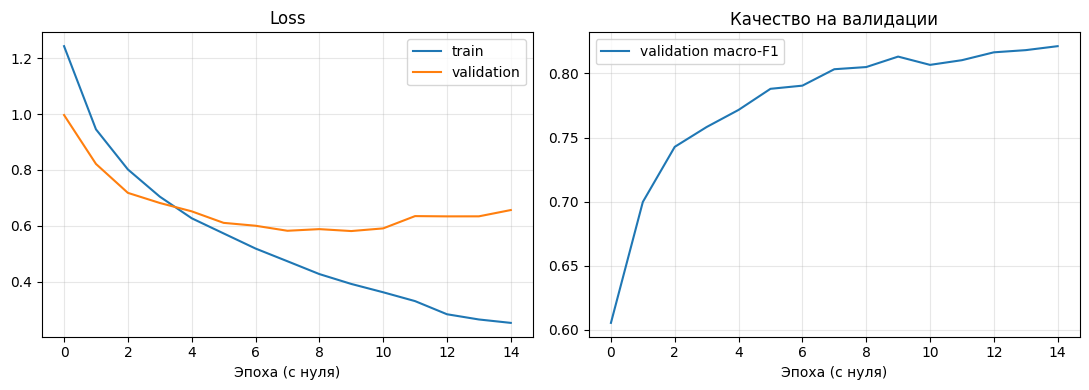

In [ ]:
test_loss6, test_f1_6, true6, pred6 = evaluate6(test_loader6)
names6 = ['Extremely Negative', 'Negative', 'Neutral', 'Positive', 'Extremely Positive']
print(f'Итоговая test macro-F1 = {test_f1_6:.4f}')
print(classification_report(true6, pred6, labels=list(range(5)), target_names=names6, zero_division=0))
print(f'Разница с сообщённым baseline 0.7636: {test_f1_6 - 0.7636:+.4f}')
print('Порог 0.8 достигнут.' if test_f1_6 >= 0.8 else
      'Порог 0.8 не достигнут в этом запуске.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([row[0] for row in history6], label='train')
axes[0].plot([row[1] for row in history6], label='validation')
axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot([row[2] for row in history6], label='validation macro-F1')
axes[1].set_title('Качество на валидации'); axes[1].legend()
for ax in axes:
    ax.set_xlabel('Эпоха (с нуля)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [ ]:
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

required = ['model6', 'device6', 'val_loader6', 'test_loader6']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Сначала выполните подготовку и обучение модели из задания 6; отсутствуют: ' + ', '.join(missing))

class_names_cal = ['Extremely Negative', 'Negative', 'Neutral', 'Positive', 'Extremely Positive']
def collect_logits_cal(loader):
    model6.eval()
    logits_all, labels_all = [], []
    with torch.no_grad():
        for tokens, lengths, labels in loader:
            logits = model6(tokens.to(device6), lengths)
            logits_all.append(logits.cpu().numpy())
            labels_all.append(labels.cpu().numpy())
    return np.concatenate(logits_all), np.concatenate(labels_all)

def macro_f1_cal(labels, logits, bias):
    return f1_score(labels, np.argmax(logits + bias, axis=1),
                    labels=list(range(5)), average='macro', zero_division=0)

val_logits_cal, val_labels_cal = collect_logits_cal(val_loader6)
try:
    tune_idx_cal, select_idx_cal = train_test_split(
        np.arange(len(val_labels_cal)), test_size=0.5, random_state=42,
        stratify=val_labels_cal)
except ValueError as error:
    raise ValueError('В валидационной выборке недостаточно примеров каждого класса для калибровки.') from error

# Четыре независимых сдвига; пятый зафиксирован в 0, так как общий сдвиг не влияет на argmax.
candidate_cal = np.zeros(5, dtype=float)
grid_cal = np.round(np.arange(-0.4, 0.41, 0.1), 1)
for _ in range(2):
    for index in range(4):
        best_value = candidate_cal[index]
        best_score = macro_f1_cal(val_labels_cal[tune_idx_cal], val_logits_cal[tune_idx_cal], candidate_cal)
        for value in sorted(grid_cal, key=lambda x: (abs(x - best_value), abs(x))):
            trial = candidate_cal.copy()
            trial[index] = value
            score = macro_f1_cal(val_labels_cal[tune_idx_cal], val_logits_cal[tune_idx_cal], trial)
            # При равенстве сохраняем текущий сдвиг, избегая лишних изменений.
            if score > best_score + 1e-12:
                best_score, best_value = score, value
        candidate_cal[index] = best_value

zero_cal = np.zeros(5, dtype=float)
raw_select_cal = macro_f1_cal(val_labels_cal[select_idx_cal], val_logits_cal[select_idx_cal], zero_cal)
bias_select_cal = macro_f1_cal(val_labels_cal[select_idx_cal], val_logits_cal[select_idx_cal], candidate_cal)
chosen_cal = candidate_cal if bias_select_cal > raw_select_cal + 1e-12 else zero_cal
print(f'Validation selection macro-F1: без сдвига {raw_select_cal:.4f}, со сдвигом {bias_select_cal:.4f}')
print('Сдвиг принят.' if np.any(chosen_cal) else 'Сдвиг не принят; используем исходные предсказания.')
print('Выбранные сдвиги по классам:', dict(zip(class_names_cal, np.round(chosen_cal, 3))))

# Тест используется только после выбора сдвига на валидации.
test_logits_cal, test_labels_cal = collect_logits_cal(test_loader6)
raw_test_cal = macro_f1_cal(test_labels_cal, test_logits_cal, zero_cal)
final_test_cal = macro_f1_cal(test_labels_cal, test_logits_cal, chosen_cal)
print(f'Test macro-F1: исходная {raw_test_cal:.4f}, после выбора сдвига {final_test_cal:.4f}')
print('Предыдущее значение 0.7829 сообщено пользователем; выше приведён новый расчёт.')
print(classification_report(test_labels_cal, np.argmax(test_logits_cal + chosen_cal, axis=1),
                            labels=list(range(5)), target_names=class_names_cal, zero_division=0))
print('Порог 0.8 достигнут.' if final_test_cal >= 0.8 else 'Порог 0.8 не достигнут в этом эксперименте.')


Validation selection macro-F1: без сдвига 0.8298, со сдвигом 0.8300
Сдвиг принят.
Выбранные сдвиги по классам: {'Extremely Negative': np.float64(0.4), 'Negative': np.float64(0.0), 'Neutral': np.float64(-0.1), 'Positive': np.float64(0.0), 'Extremely Positive': np.float64(0.0)}
Test macro-F1: исходная 0.7829, после выбора сдвига 0.7846
Предыдущее значение 0.7829 сообщено пользователем; выше приведён новый расчёт.
                    precision    recall  f1-score   support

Extremely Negative       0.78      0.82      0.80       592
          Negative       0.74      0.74      0.74      1041
           Neutral       0.90      0.78      0.83       619
          Positive       0.70      0.79      0.74       947
Extremely Positive       0.87      0.75      0.80       599

          accuracy                           0.77      3798
         macro avg       0.80      0.78      0.78      3798
      weighted avg       0.78      0.77      0.78      3798

Порог 0.8 не достигнут в этом эксперименте

еще попытка

In [ ]:
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from torch import nn
from torch.nn.utils import clip_grad_norm_
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)
if device.type != 'cuda':
    print('GPU не обнаружен: обучение на CPU может занять очень много времени.')

Устройство: cuda


In [ ]:
required = ('df_train', 'df_val', 'df_test')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Не найдены данные в текущей среде: ' + ', '.join(missing) +
                       '. Запустите ячейки подготовки данных из предыдущего ноутбука.')

label_names = ['Extremely Negative', 'Negative', 'Neutral', 'Positive', 'Extremely Positive']
label_to_id = {name: i for i, name in enumerate(label_names)}
train_df, val_df, test_df = (frame[['OriginalTweet', 'Sentiment']].dropna().copy()
                             for frame in (df_train, df_val, df_test))
for frame in (train_df, val_df, test_df):
    unknown = set(frame['Sentiment']) - set(label_names)
    if unknown:
        raise ValueError(f'Неизвестные метки: {unknown}')
print(f'Обучение: {len(train_df)}, валидация: {len(val_df)}, тест: {len(test_df)}')

Обучение: 34983, валидация: 6174, тест: 3798


In [ ]:
MODEL_NAME = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 128
BATCH_SIZE = 16
NUM_EPOCHS = 4
PATIENCE = 2
CHECKPOINT = 'best_distilbert_bigru.pt'

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def clean_tweet(text):
    return re.sub(r'https?://\S+|www\.\S+|@\w+', ' ', str(text))

class TweetDataset(Dataset):
    def __init__(self, frame):
        texts = [clean_tweet(text) for text in frame['OriginalTweet']]
        self.encoded = tokenizer(texts, truncation=True, max_length=MAX_LENGTH)
        self.labels = [label_to_id[value] for value in frame['Sentiment']]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {name: values[index] for name, values in self.encoded.items()}
        item['labels'] = self.labels[index]
        return item

# Динамический padding: длина батча равна длине самого длинного текста в нём.
def collate_batch(items):
    label_ids = torch.tensor([item['labels'] for item in items], dtype=torch.long)
    features = [{key: value for key, value in item.items() if key != 'labels'} for item in items]
    batch = tokenizer.pad(features, padding=True, return_tensors='pt')
    batch['labels'] = label_ids
    return batch

train_set, val_set, test_set = (TweetDataset(frame) for frame in (train_df, val_df, test_df))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
# Токенизируем обучающие тексты без обрезки, чтобы измерить её влияние.
original_lengths = [len(tokenizer.encode(clean_tweet(text), truncation=False))
                    for text in train_df['OriginalTweet']]
truncated = sum(length > MAX_LENGTH for length in original_lengths)
print(f'Длиннее {MAX_LENGTH} токенов: {truncated}/{len(original_lengths)} '
      f'({100 * truncated / len(original_lengths):.2f}% обучающих твитов)')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Длиннее 128 токенов: 23/34983 (0.07% обучающих твитов)


In [ ]:
class DistilBertBiGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        embedding_size = self.encoder.config.hidden_size
        self.gru = nn.GRU(embedding_size, 128, num_layers=1,
                          batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.25)
        self.classifier = nn.Linear(embedding_size + 256, len(label_names))

    def forward(self, input_ids, attention_mask):
        encoded = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        lengths = attention_mask.sum(dim=1).cpu()
        packed = pack_padded_sequence(encoded, lengths, batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        context = torch.cat((encoded[:, 0, :], hidden[-2], hidden[-1]), dim=1)
        return self.classifier(self.dropout(context))

model = DistilBertBiGRU().to(device)
optimizer = torch.optim.AdamW([
    {'params': model.encoder.parameters(), 'lr': 2e-5},
    {'params': list(model.gru.parameters()) + list(model.classifier.parameters()), 'lr': 1e-3}
], weight_decay=0.01)
loss_fn = nn.CrossEntropyLoss()
total_steps = len(train_loader) * NUM_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps),
                                            num_training_steps=total_steps)
print('Пакетов за эпоху:', len(train_loader))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Пакетов за эпоху: 2187


In [ ]:
def collect_predictions(loader):
    model.eval()
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch['labels']
            inputs = {key: batch[key].to(device) for key in ('input_ids', 'attention_mask')}
            logits = model(**inputs)
            all_labels.extend(labels.tolist())
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())
    return all_labels, all_predictions

best_val_f1 = -1.0
best_epoch = 0
stale_epochs = 0
history = []
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    loss_sum = 0.0
    examples = 0
    for step, batch in enumerate(train_loader, start=1):
        labels = batch['labels'].to(device)
        inputs = {key: batch[key].to(device) for key in ('input_ids', 'attention_mask')}
        optimizer.zero_grad(set_to_none=True)
        logits = model(**inputs)
        loss = loss_fn(logits, labels)
        loss.backward()
        clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        loss_sum += loss.item() * labels.size(0)
        examples += labels.size(0)
        if step % 250 == 0:
            print(f'Эпоха {epoch}, пакет {step}/{len(train_loader)}, loss = {loss_sum / examples:.4f}')

    val_labels, val_predictions = collect_predictions(val_loader)
    val_f1 = f1_score(val_labels, val_predictions, labels=list(range(5)),
                      average='macro', zero_division=0)
    history.append((epoch, loss_sum / examples, val_f1))
    print(f'Эпоха {epoch}: train loss = {loss_sum / examples:.4f}, val macro-F1 = {val_f1:.4f}')
    if val_f1 > best_val_f1:
        best_val_f1, best_epoch, stale_epochs = val_f1, epoch, 0
        # Сохраняем веса на CPU, не удерживая вторую копию модели на GPU.
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, CHECKPOINT)
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print('Ранняя остановка по качеству на валидации.')
            break
print(f'Лучшая эпоха: {best_epoch}, macro-F1 на валидации: {best_val_f1:.4f}')

Эпоха 1, пакет 250/2187, loss = 0.6143
Эпоха 1, пакет 500/2187, loss = 0.6043
Эпоха 1, пакет 750/2187, loss = 0.5845
Эпоха 1, пакет 1000/2187, loss = 0.5706
Эпоха 1, пакет 1250/2187, loss = 0.5639
Эпоха 1, пакет 1500/2187, loss = 0.5579
Эпоха 1, пакет 1750/2187, loss = 0.5497
Эпоха 1, пакет 2000/2187, loss = 0.5401
Эпоха 1: train loss = 0.5341, val macro-F1 = 0.8354
Эпоха 2, пакет 250/2187, loss = 0.3776
Эпоха 2, пакет 500/2187, loss = 0.3454
Эпоха 2, пакет 750/2187, loss = 0.3421
Эпоха 2, пакет 1000/2187, loss = 0.3471
Эпоха 2, пакет 1250/2187, loss = 0.3435
Эпоха 2, пакет 1500/2187, loss = 0.3438
Эпоха 2, пакет 1750/2187, loss = 0.3419
Эпоха 2, пакет 2000/2187, loss = 0.3388
Эпоха 2: train loss = 0.3382, val macro-F1 = 0.8619
Эпоха 3, пакет 250/2187, loss = 0.2434
Эпоха 3, пакет 500/2187, loss = 0.2432
Эпоха 3, пакет 750/2187, loss = 0.2454
Эпоха 3, пакет 1000/2187, loss = 0.2425
Эпоха 3, пакет 1250/2187, loss = 0.2394
Эпоха 3, пакет 1500/2187, loss = 0.2376
Эпоха 3, пакет 1750/2187,

Лучшая валидация: 0.8724 (эпоха 3)
Macro-F1 на тесте: 0.8530
                    precision    recall  f1-score   support

Extremely Negative       0.87      0.87      0.87       592
          Negative       0.83      0.85      0.84      1041
           Neutral       0.88      0.85      0.86       619
          Positive       0.81      0.84      0.82       947
Extremely Positive       0.91      0.83      0.87       599

          accuracy                           0.85      3798
         macro avg       0.86      0.85      0.85      3798
      weighted avg       0.85      0.85      0.85      3798

Ранее сообщённый результат базовой LSTM: 0.7636
Разница с ним: +0.0894
Порог 0,8 достигнут.


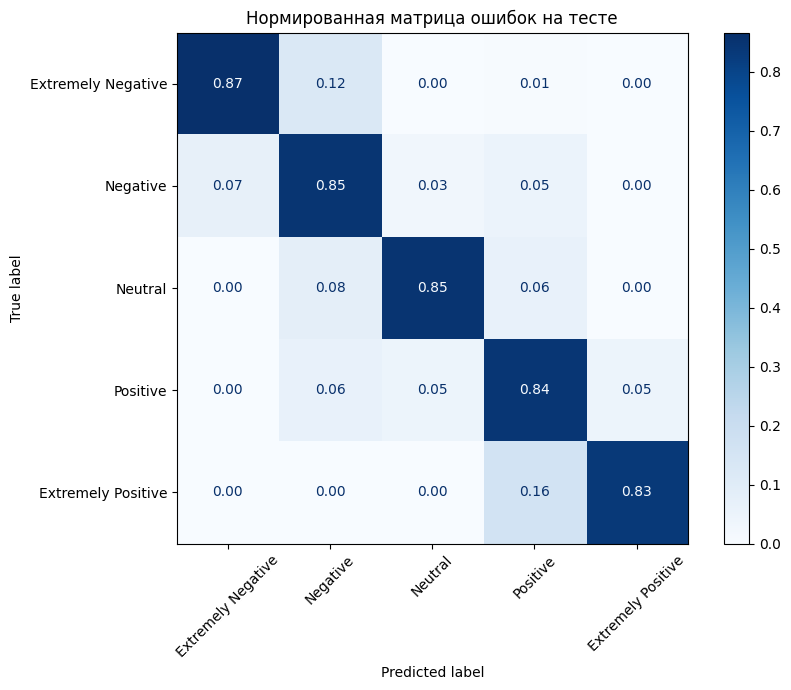

In [ ]:
model.load_state_dict(torch.load(CHECKPOINT, map_location=device, weights_only=True))
test_labels, test_predictions = collect_predictions(test_loader)
test_f1 = f1_score(test_labels, test_predictions, labels=list(range(5)),
                   average='macro', zero_division=0)
print(f'Лучшая валидация: {best_val_f1:.4f} (эпоха {best_epoch})')
print(f'Macro-F1 на тесте: {test_f1:.4f}')
print(classification_report(test_labels, test_predictions, labels=list(range(5)),
                            target_names=label_names, zero_division=0))
previous_baseline = 0.7636
print(f'Ранее сообщённый результат базовой LSTM: {previous_baseline:.4f}')
print(f'Разница с ним: {test_f1 - previous_baseline:+.4f}')
print('Порог 0,8 достигнут.' if test_f1 >= 0.8 else
      'Порог 0,8 не достигнут в этом запуске.')
cm = confusion_matrix(test_labels, test_predictions, labels=list(range(5)), normalize='true')
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(ax=ax, xticks_rotation=45,
                                                           values_format='.2f', cmap='Blues')
plt.title('Нормированная матрица ошибок на тесте')
plt.tight_layout()
plt.show()